In [ ]:
# run when connecting aws instance

import os
import psutil

vcpus = os.cpu_count()
total_ram = round(psutil.virtual_memory().total / (1024**3), 2)

print(f"Active vCPUs : {vcpus}")
print(f"Total RAM   : {total_ram} GB")

Active vCPUs : 16
Total RAM   : 31.28 GB


Installing Schedule

In [ ]:
!pip install schedule

Importing pandas, schedule, time, logging

In [ ]:
import pandas as pd
import numpy as np
import schedule
import time
import logging

Creating the log file

In [ ]:
#logging

log_file = '/content/drive/MyDrive/DSA/Traffic Prediction Project/et1.csv'

# log_file = 'et1.csv'

#Removing Handlers
for handler in logging.root.handlers[:]:
  logging.root.removeHandler(handler)

# config your logging
logging.basicConfig(
    level = logging.INFO,
    format = '%(asctime)s - %(levelname)s - %(message)s',
    handlers = [
        logging.StreamHandler(),
        logging.FileHandler(log_file,mode='a')
    ],force=True
)
logger = logging.getLogger('ETL')
logger.info('Logging System Started')

2026-11-06 10:56:27,589 - INFO - Logging System Started


# ETL


Creating the csv file

In [ ]:
# checking available packages in the environment (osmnx, networkx, geopandas, shapely, etc.)
for pkg in ['networkx', 'geopandas', 'shapely', 'osmnx', 'requests']:
    try:
        __import__(pkg)
        print(f"{pkg}: available")
    except ImportError:
        print(f"{pkg}: NOT available")

networkx: available
geopandas: available
shapely: available
osmnx: NOT available
requests: available


In [ ]:
# installing osmnx
!pip install osmnx

In [ ]:
import osmnx as ox # connecting open street map api
import geopandas as gpd # Extends pandas to handle geospatial vector data (points, lines, polygons).

# Configure settings: Custom User-Agent prevents HTTP 403 / 406 blocks
ox.settings.user_agent = "TrivandrumTrafficPredictor/1.0 (academic_research)" # entering the domain
ox.settings.use_cache = True  # to download chache file locally
ox.settings.log_console = True # Prints real-time debug/status logs

print("Downloading Trivandrum street network...")

# 1. Download drivable street graph
# 'drive' includes motorways, trunks, primary, secondary, tertiary, and residential roads
G = ox.graph_from_place(
    "Thiruvananthapuram, Kerala, India",
    network_type="drive",
    simplify=True  # Simplifies curves into clean intersection-to-intersection links
)

print(f"Graph loaded successfully: {len(G.nodes)} intersections, {len(G.edges)} road links!")

Graph loaded successfully: 71786 intersections, 171980 road links!


In [ ]:
# Convert to GeoPandas GeoDataFrames
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G) # Splits the graph into two geopandas.GeoDataFrame objects:

# nodes_gdf: Contains point geometries of all intersections/nodes, indexed by node ID (osmid),
#with attributes like latitude (y) and longitude (x).

# edges_gdf: Contains LineString geometries of road segments, with a MultiIndex (u, v, key) representing:

# u: Origin node ID.
# v: Destination node ID.
# key: Edge identifier (differentiates multiple parallel edges between the same two nodes, e.g., dual carriageways).

# Reset multi-index to standard columns (u, v, key)
edges_df = edges_gdf.reset_index()

# Extract coordinates for map plotting (start & end coordinates)
edges_df['start_lat'] = edges_df['u'].map(nodes_gdf['y'])
edges_df['start_lon'] = edges_df['u'].map(nodes_gdf['x'])
edges_df['end_lat'] = edges_df['v'].map(nodes_gdf['y'])
edges_df['end_lon'] = edges_df['v'].map(nodes_gdf['x'])

# Create unique road segment identifier (analogous to Product_Name)
edges_df['segment_id'] = edges_df['u'].astype(str) + "_" + edges_df['v'].astype(str)

# Keep relevant columns for traffic analysis
# Updated list of columns for road network export and time-series forecasting
cols_to_keep = [
    # Network Graph & Segment Identification
    'u', 'v', 'key', 'segment_id',

    # Temporal & Forecasting Target
    'date_time', 'traffic_volume',

    # Road Infrastructure & Capacity Attributes
    'name', 'highway', 'length', 'lanes', 'maxspeed', 'oneway',
    'capacity_pcu', 'vc_ratio',

    # Regional Grouping
    'region',

    # Spatial Endpoints & Geometry
    'start_lat', 'start_lon', 'end_lat', 'end_lon', 'geometry'
]
available_cols = [c for c in cols_to_keep if c in edges_df.columns]
clean_edges_df = edges_df[available_cols]

# Save to CSV and GeoJSON
clean_edges_df.to_csv("/content/drive/MyDrive/DSA/Traffic Prediction Project/trivandrum_osm_roads.csv", index=False)
edges_gdf.to_file("/content/drive/MyDrive/DSA/Traffic Prediction Project/trivandrum_osm_roads.geojson", driver="GeoJSON")

# clean_edges_df.to_csv("trivandrum_osm_roads.csv", index=False)
# edges_gdf.to_file("trivandrum_osm_roads.geojson", driver="GeoJSON")

print("Saved 'trivandrum_osm_roads.csv' and 'trivandrum_osm_roads.geojson' successfully!")

Saved 'trivandrum_osm_roads.csv' and 'trivandrum_osm_roads.geojson' successfully!


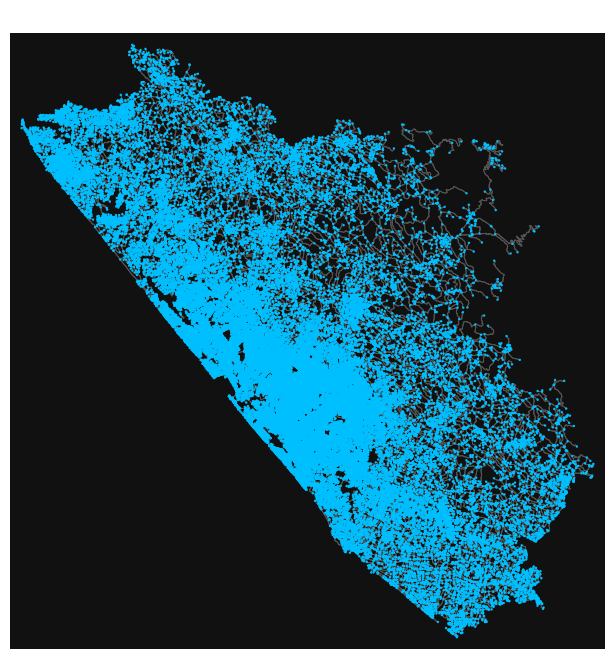

In [ ]:
import matplotlib.pyplot as plt
import osmnx as ox

# Ensure osmnx registers matplotlib by calling the plot function after explicit imports
fig, ax = ox.plot_graph(
    G,
    node_size=3,
    node_color="deepskyblue",
    edge_color="#555555",
    edge_linewidth=0.7,
    bgcolor="#111111",
    show=False,
    close=False
)
plt.title("Thiruvananthapuram Drivable Road Graph", color="white", fontsize=14)
plt.show()

Transform

In [ ]:
import pandas as pd
import numpy as np
import datetime

# Load the downloaded OSM roads
osm_roads_path = "/content/drive/MyDrive/DSA/Traffic Prediction Project/trivandrum_osm_roads.csv"
# osm_roads_path = "trivandrum_osm_roads.csv"
osm_df = pd.read_csv(osm_roads_path)

print(f"Loaded {len(osm_df)} raw OSM links.")

# Standardize the 'highway' column as it can contain list-like strings or unhandled subtypes
def clean_highway(val):
    if pd.isna(val):
        return 'unclassified'
    val = str(val).lower()
    if '[' in val or ']' in val:
        # Handle list strings like ['primary', 'link']
        val = val.replace('[', '').replace(']', '').replace("'", "").replace('"', '').split(',')[0].strip()
    return val.strip()

osm_df['cleaned_highway'] = osm_df['highway'].apply(clean_highway)
print("Top highway classifications:")
print(osm_df['cleaned_highway'].value_counts().head(10))

Loaded 171980 raw OSM links.
Top highway classifications:
cleaned_highway
residential       111738
unclassified       27008
secondary          13690
tertiary           12786
primary             4449
living_street       1528
trunk                528
primary_link          98
secondary_link        63
trunk_link            33
Name: count, dtype: int64


In [ ]:
import os
import datetime
import requests
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Load and Preprocess Base OSM Road Data
# ---------------------------------------------------------
osm_roads_path = "/content/drive/MyDrive/DSA/Traffic Prediction Project/trivandrum_osm_roads.csv"
# osm_roads_path = "trivandrum_osm_roads.csv"
if not os.path.exists(osm_roads_path):
    raise FileNotFoundError(
        f"Could not find base OSM file at: {osm_roads_path}. Please re-run the download cells."
    )

osm_df = pd.read_csv(osm_roads_path)

def clean_highway(val):
    if pd.isna(val):
        return 'unclassified'
    val = str(val).lower()
    if '[' in val or ']' in val:
        val = val.replace('[', '').replace(']', '').replace("'", "").replace('"', '').split(',')[0].strip()
    return val.strip()

osm_df['cleaned_highway'] = osm_df['highway'].apply(clean_highway)

# Map OSM classifications to engineering capacities (PCU) and free-flow speeds (km/h)
capacity_map = {
    'motorway': 6000, 'motorway_link': 3000,
    'trunk': 4500, 'trunk_link': 2500,
    'primary': 3500, 'primary_link': 1800,
    'secondary': 2200, 'secondary_link': 1200,
    'tertiary': 1500, 'tertiary_link': 800,
    'residential': 1000,
    'living_street': 600,
    'unclassified': 1000
}

ffs_map = {
    'motorway': 80, 'motorway_link': 50,
    'trunk': 65, 'trunk_link': 45,
    'primary': 45, 'primary_link': 35,
    'secondary': 35, 'secondary_link': 30,
    'tertiary': 30, 'tertiary_link': 25,
    'residential': 25,
    'living_street': 15,
    'unclassified': 20
}

osm_df['capacity_pcu'] = osm_df['cleaned_highway'].map(capacity_map).fillna(1000).astype(int)
osm_df['free_flow_speed_kmh'] = osm_df['cleaned_highway'].map(ffs_map).fillna(20).astype(int)

# Focus simulation strictly on major arterial lines
arterial_df = osm_df[osm_df['cleaned_highway'].isin(['trunk', 'primary', 'secondary', 'motorway'])].copy()
print(f"Targeted simulation subset: {len(arterial_df)} major arterial road segments.")

# Pre-extract arrays for vectorization
capacities = arterial_df['capacity_pcu'].values
ff_speeds = arterial_df['free_flow_speed_kmh'].values
lengths_km = (arterial_df['length'] / 1000.0).values
osm_u = arterial_df['u'].values
osm_v = arterial_df['v'].values
road_names = arterial_df['name'].values
road_highways = arterial_df['cleaned_highway'].values
num_links = len(arterial_df)

# ---------------------------------------------------------
# 2. Comprehensive Calendar & Regional Holiday Mapping (2025)
# ---------------------------------------------------------
holiday_mapping = {
    # --- January ---
    "2025-01-01": "New Year's Day",
    "2025-01-26": "Republic Day",

    # --- February & March ---
    "2025-02-26": "Maha Shivratri",
    "2025-03-12": "Attukal Pongala Eve",
    "2025-03-13": "Attukal Pongala Day",
    "2025-03-30": "Eid ul-Fitr Eve",
    "2025-03-31": "Eid ul-Fitr",

    # --- April & May (Festivals & Vacations) ---
    "2025-04-03": "Maundy Thursday",
    "2025-04-13": "Vishu Eve",
    "2025-04-14": "Vishu",
    "2025-04-18": "Good Friday",
    "2025-04-20": "Easter Sunday",
    "2025-04-21": "Easter Return Rush",
    "2025-05-01": "May Day",

    # --- June & July (School Reopening & Monsoon) ---
    "2025-06-02": "School Reopening Day",
    "2025-06-06": "Bakrid Eve",
    "2025-06-07": "Bakrid",
    "2025-06-16": "Mid-Monsoon Day",
    "2025-07-06": "Muharram",
    "2025-07-15": "Heavy Monsoon Day",

    # --- August & September (Onam Season & National Holidays) ---
    "2025-08-14": "Independence Day Eve",
    "2025-08-15": "Independence Day",
    "2025-08-28": "Atham / Pre-Onam Rush Start",
    "2025-08-31": "Pre-Onam Sunday",
    "2025-09-04": "Uthradom",
    "2025-09-05": "Thiruvonam / Milad-i-Sherif",
    "2025-09-06": "Third Onam",
    "2025-09-07": "Fourth Onam / Chathayam",
    "2025-09-08": "Post-Onam Reopening Day",
    "2025-09-21": "Sree Narayana Guru Samadhi",

    # --- October & November ---
    "2025-10-01": "Mahanavami",
    "2025-10-02": "Vijayadashami / Gandhi Jayanti",
    "2025-10-19": "Deepavali Eve",
    "2025-10-20": "Deepavali",
    "2025-11-01": "Kerala Piravi",
    "2025-11-16": "Mandala Season Start",

    # --- December (Year-end & Christmas Rush) ---
    "2025-12-23": "Christmas Eve-Eve",
    "2025-12-24": "Christmas Eve",
    "2025-12-25": "Christmas Day",
    "2025-12-26": "Post-Christmas Day",
    "2025-12-31": "New Year's Eve"
}

# Distinct behavioural sub-categories
pre_festivals_set = {
    "2025-03-12", "2025-03-30", "2025-04-13", "2025-06-06",
    "2025-08-14", "2025-08-28", "2025-08-31", "2025-09-04",
    "2025-10-19", "2025-12-23", "2025-12-24", "2025-12-31"
}

representative_dates = list(holiday_mapping.keys())

# ---------------------------------------------------------
# 3. Retrieve Historical Weather (Open-Meteo)
# ---------------------------------------------------------
LATITUDE = 8.5241
LONGITUDE = 76.9366
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "hourly": ["precipitation", "weather_code"],
    "timezone": "Asia/Kolkata"
}

response = requests.get(ARCHIVE_URL, params=weather_params)
response.raise_for_status()
weather_json = response.json()

df_rain_2025 = pd.DataFrame({
    "timestamp": pd.to_datetime(weather_json["hourly"]["time"]),
    "rain_mm": weather_json["hourly"]["precipitation"]
})

df_rain_2025["month"] = df_rain_2025["timestamp"].dt.month
df_rain_2025["day"] = df_rain_2025["timestamp"].dt.day
df_rain_2025["hour"] = df_rain_2025["timestamp"].dt.hour

def classify_weather(mm):
    if mm == 0.0: return "Clear"
    elif mm < 2.5: return "Light Rain"
    elif mm <= 7.5: return "Moderate Rain"
    elif mm <= 15.0: return "Heavy Rain"
    else: return "Very Heavy Rain"

df_rain_2025["weather_category"] = df_rain_2025["rain_mm"].apply(classify_weather)
rain_lookup = df_rain_2025.set_index(["month", "day", "hour"])[["rain_mm", "weather_category"]].to_dict(orient="index")

# ---------------------------------------------------------
# 4. Batch Vector-Based Traffic Simulation
# ---------------------------------------------------------
np.random.seed(42)
sim_records = []

print(f"Simulating all {len(representative_dates)} dates across 24 hours on {num_links} links...")

for d_str in representative_dates:
    base_date = datetime.datetime.strptime(d_str, "%Y-%m-%d")
    m, d_val = base_date.month, base_date.day
    dow = base_date.weekday()
    is_weekend = 1 if dow in [5, 6] else 0
    holiday_name = holiday_mapping.get(d_str, "None")
    is_holiday = 1 if holiday_name != "None" else 0
    is_pre_festival = 1 if d_str in pre_festivals_set else 0

    for h in range(24):
        rain_info = rain_lookup.get((m, d_val, h), {"rain_mm": 0.0, "weather_category": "Clear"})
        rain_mm = rain_info["rain_mm"]
        weather = rain_info["weather_category"]

        # Diurnal volume-to-capacity base distribution
        if h < 5:
            ratios = np.random.uniform(0.05, 0.15, num_links)
        elif 5 <= h < 8:
            ratios = np.random.uniform(0.18, 0.40, num_links)
        elif 8 <= h <= 11:
            ratios = np.random.uniform(0.70, 0.95, num_links)
        elif 11 < h < 16:
            ratios = np.random.uniform(0.45, 0.65, num_links)
        elif 16 <= h <= 20:
            ratios = np.random.uniform(0.75, 1.00, num_links)
        else:
            ratios = np.random.uniform(0.15, 0.35, num_links)

        # Behavioral adjustment for pre-festival shopping / market surges
        if is_pre_festival and (10 <= h <= 21):
            ratios *= np.random.uniform(1.15, 1.35, num_links)

        # Behavioral adjustment for strict public holidays (office commute reduction)
        elif is_holiday and not is_pre_festival and (8 <= h <= 19):
            ratios *= np.random.uniform(0.60, 0.80, num_links)

        # Weather factor: Rain dampening / demand variation (corrected syntax)
        if rain_mm > 0:
            rain_dampening_factor = 1.0 + min(0.30, 0.05 + (rain_mm / 20.0) * 0.25)
            ratios *= rain_dampening_factor

        # BPR (Bureau of Public Roads) speed-flow relationship
        volumes = np.clip(ratios * capacities, 15, capacities * 1.45).astype(int)
        vc_ratios = volumes / capacities

        # Corrected mathematical formula
        speeds = ff_speeds / (1.0 + 0.4 * (vc_ratios ** 3.6))
        speeds = np.clip(speeds, 5.0, ff_speeds)

        if rain_mm > 5.0:
            speeds = np.clip(speeds * 0.75, 5.0, ff_speeds)

        # Corrected travel time equation
        travel_times_min = (lengths_km / speeds) * 60.0

        temp_df = pd.DataFrame({
            'date_time': f"{d_str} {h:02d}:00:00",
            'osm_u': osm_u,
            'osm_v': osm_v,
            'name': road_names,
            'highway': road_highways,
            'length_km': np.round(lengths_km, 3),
            'capacity_pcu': capacities,
            'free_flow_speed_kmh': ff_speeds,
            'traffic_volume': volumes,
            'vc_ratio': np.round(vc_ratios, 2),
            'avg_speed_kmh': np.round(speeds, 1),
            'travel_time_min': np.round(travel_times_min, 2),
            'weather': weather,
            'rain_mm': rain_mm,
            'is_weekend': is_weekend,
            'is_holiday': is_holiday,
            'is_pre_festival': is_pre_festival,
            'holiday': holiday_name
        })
        sim_records.append(temp_df)

osm_simulated_df = pd.concat(sim_records, ignore_index=True)
print(f"Simulation finished! Total generated records: {len(osm_simulated_df)}")

Targeted simulation subset: 18669 major arterial road segments.
Simulating all 41 dates across 24 hours on 18669 links...
Simulation finished! Total generated records: 18370296


IRC: 106-1990 / IRC: 106-2022 (Guidelines for Capacity of Urban Roads in Plain Areas):Provides base capacities in PCU/hr (Passenger Car Units per hour) based on carriageway configurations:   2-lane undivided (collector / tertiary / secondary): ~1,200–1,500 PCU/h.   4-lane divided (primary / sub-arterial): ~3,500–4,000 PCU/h.6-lane divided / expressways (trunk / motorway): ~5,400–6,000+ PCU/h.IRC: 86-1983 / IRC: 86-2018 (Geometric Design Standards for Urban Roads in Plains):Defines urban road classification (Arterials, Sub-Arterials, Collectors, Local Streets) and establishes recommended urban design speeds / operating speeds (ranging from 15–20 km/h for access/living streets up to 60–80 km/h for controlled-access corridors).

Load

In [ ]:
# Save the generated actual OSM traffic dataset to Google Drive
osm_output_path = "/content/drive/MyDrive/DSA/Traffic Prediction Project/Trivandrum_OSM_Real_Traffic_Dataset.csv"
# osm_output_path = "Trivandrum_OSM_Real_Traffic_Dataset.csv"

osm_simulated_df.to_csv(osm_output_path, index=False)
print(f"Successfully saved to: {osm_output_path}")
display(osm_simulated_df.head())

# Show dataset statistics
print("Average Speed & Volumes by Road Class:")
print(osm_simulated_df.groupby('highway')[['traffic_volume', 'avg_speed_kmh']].mean())

Successfully saved to: /content/drive/MyDrive/DSA/Traffic Prediction Project/Trivandrum_OSM_Real_Traffic_Dataset.csv


,date_time,osm_u,osm_v,name,highway,length_km,capacity_pcu,free_flow_speed_kmh,traffic_volume,vc_ratio,avg_speed_kmh,travel_time_min,weather,rain_mm,is_weekend,is_holiday,is_pre_festival,holiday
0,2025-01-01 00:00:00,245581590,6344359035,NaN,primary,0.031,3500,45,306,0.09,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
1,2025-01-01 00:00:00,245581590,6953034607,NaN,primary,0.028,3500,45,507,0.14,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
2,2025-01-01 00:00:00,245581703,2629684304,Nedumangad - Mancha Road,primary,0.027,3500,45,431,0.12,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
3,2025-01-01 00:00:00,245581703,2629684313,NaN,secondary,0.054,2200,35,241,0.11,35.0,0.09,Clear,0.0,0,1,0,New Year's Day
4,2025-01-01 00:00:00,245581703,1626528966,Nedumangad - Shorlacode Road,primary,0.045,3500,45,229,0.07,45.0,0.06,Clear,0.0,0,1,0,New Year's Day


Average Speed & Volumes by Road Class:
           traffic_volume  avg_speed_kmh
highway                                 
motorway      2738.082825      74.695224
primary       1595.325637      42.030990
secondary     1002.555545      32.691635
trunk         2050.840618      60.712750


In [ ]:
!pip install gdown

import gdown

# Replace with your file ID (the long string between /d/ and /view in the shareable link)
url = "https://drive.google.com/file/d/12HDSubrSvKk572Ya8yHNGr93aA1iMeSQ/view?usp=drive_link"

# Downloads directly into your EC2 instance's current directory
output = "Trivandrum_OSM_Real_Traffic_Dataset.csv"  # or data.csv
gdown.download(url, output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=12HDSubrSvKk572Ya8yHNGr93aA1iMeSQ
From (redirected): https://drive.google.com/uc?id=12HDSubrSvKk572Ya8yHNGr93aA1iMeSQ&confirm=t&uuid=f64753c3-116b-4245-8ab7-d2f280156038
To: /home/azureuser/Trivandrum_OSM_Real_Traffic_Dataset.csv
100%|█████████████████████████████| 2.61G/2.61G [00:27<00:00, 94.1MB/s]


'Trivandrum_OSM_Real_Traffic_Dataset.csv'

In [ ]:
import pandas as pd

# changing the name
# df = pd.read_csv('/content/drive/MyDrive/DSA/Traffic Prediction Project/Trivandrum_OSM_Real_Traffic_Dataset.csv')
df = pd.read_csv('Trivandrum_OSM_Real_Traffic_Dataset.csv')

In [ ]:
df

,date_time,osm_u,osm_v,name,highway,length_km,capacity_pcu,free_flow_speed_kmh,traffic_volume,vc_ratio,avg_speed_kmh,travel_time_min,weather,rain_mm,is_weekend,is_holiday,is_pre_festival,holiday
0,2025-01-01 00:00:00,245581590,6344359035,NaN,primary,0.031,3500,45,306,0.09,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
1,2025-01-01 00:00:00,245581590,6953034607,NaN,primary,0.028,3500,45,507,0.14,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
2,2025-01-01 00:00:00,245581703,2629684304,Nedumangad - Mancha Road,primary,0.027,3500,45,431,0.12,45.0,0.04,Clear,0.0,0,1,0,New Year's Day
3,2025-01-01 00:00:00,245581703,2629684313,NaN,secondary,0.054,2200,35,241,0.11,35.0,0.09,Clear,0.0,0,1,0,New Year's Day
4,2025-01-01 00:00:00,245581703,1626528966,Nedumangad - Shorlacode Road,primary,0.045,3500,45,229,0.07,45.0,0.06,Clear,0.0,0,1,0,New Year's Day
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18370291,2025-12-31 23:00:00,14354092974,7507372695,Punnamoodu to Peringammala Road,secondary,0.188,2200,35,565,0.26,34.9,0.32,Clear,0.0,0,1,1,New Year's Eve
18370292,2025-12-31 23:00:00,14354092980,4527697705,Punnamoodu to Peringammala Road,secondary,0.074,2200,35,353,0.16,35.0,0.13,Clear,0.0,0,1,1,New Year's Eve
18370293,2025-12-31 23:00:00,14354092980,14354092965,Punnamoodu to Peringammala Road,secondary,0.172,2200,35,606,0.28,34.9,0.30,Clear,0.0,0,1,1,New Year's Eve
18370294,2025-12-31 23:00:00,14354092991,7544877375,Punnamoodu to Peringammala Road,secondary,0.049,2200,35,679,0.31,34.8,0.08,Clear,0.0,0,1,1,New Year's Eve
